# Multiple Linear Regression with a Medical Dataset
## Predicting diabetes disease progression from baseline patient measurements

This notebook uses the **Diabetes dataset** distributed with scikit-learn.

The response variable is a quantitative measure of **disease progression one year after baseline**.

We will predict

$$
Y=\text{disease progression}
$$

using several baseline predictors, including:

$$
X_1=\text{BMI},\qquad
X_2=\text{blood pressure},\qquad
X_3=\text{age},
$$

plus several blood-serum measurements.

The multiple linear regression model is

$$
\boxed{
\mathbb E[Y\mid X_1,\ldots,X_p]
=
\beta_0+\beta_1X_1+\cdots+\beta_pX_p.
}
$$

The main conceptual question is:

$$
\boxed{
\text{What does }\beta_j\text{ mean when several patient variables are in the model at once?}
}
$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t

df = pd.read_csv("diabetes_regression_data.csv")

print(f"n = {len(df)}")
df.head()

n = 442


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 1. Variables in the dataset

The predictor columns are:

- `age`
- `sex`
- `bmi`
- `bp`
- `s1`, `s2`, `s3`, `s4`, `s5`, `s6`

and the response is

- `target`

The predictors have already been standardized in this dataset.

So coefficient magnitudes are best interpreted as changes in expected response per one unit of the standardized predictor, rather than in raw clinical units.

In [2]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,442.0,-7.284269e-18,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,2.348549e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.087320e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.571507e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-9.293722e-18,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,4.420798e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,2.135044e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,2.913707e-17,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.143013e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.431736e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


## 2. Start with one predictor: BMI

First fit

$$
\mathbb E[Y\mid X_{\mathrm{BMI}}=x]
=
\beta_0+\beta_1x.
$$

This is a **simple linear regression**.

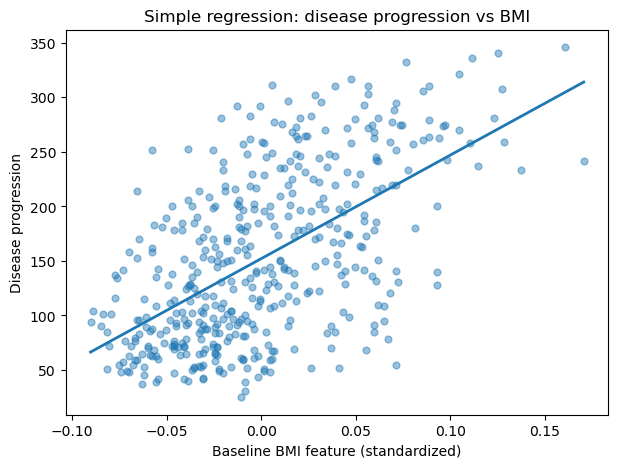

beta0_hat = 152.133
beta1_hat = 949.435


In [3]:
x = df["bmi"].to_numpy()
y = df["target"].to_numpy()

b1 = np.sum((x-x.mean())*(y-y.mean())) / np.sum((x-x.mean())**2)
b0 = y.mean() - b1*x.mean()

xx = np.linspace(x.min(), x.max(), 200)

plt.figure(figsize=(7,5))
plt.scatter(x, y, alpha=0.45, s=24)
plt.plot(xx, b0+b1*xx, linewidth=2)
plt.xlabel("Baseline BMI feature (standardized)")
plt.ylabel("Disease progression")
plt.title("Simple regression: disease progression vs BMI")
plt.show()

print(f"beta0_hat = {b0:.3f}")
print(f"beta1_hat = {b1:.3f}")

The simple-regression slope answers:

> How does expected disease progression change as BMI changes, without controlling for the other baseline variables?

## 3. Multiple regression: BMI, blood pressure, and age

Now fit

$$
\boxed{
Y
=
\beta_0
+\beta_1(\mathrm{BMI})
+\beta_2(\mathrm{BP})
+\beta_3(\mathrm{Age})
+\varepsilon.
}
$$

The interpretation changes.

For example,

$$
\beta_1
$$

now means:

$$
\boxed{
\text{change in expected disease progression as BMI changes,}
\quad
\text{holding blood pressure and age fixed.}
}
$$

In [4]:
features = ["bmi", "bp", "age"]

X = df[features].to_numpy()
y = df["target"].to_numpy()

X_design = np.column_stack([np.ones(len(df)), X])

beta_hat, *_ = np.linalg.lstsq(X_design, y, rcond=None)

pd.DataFrame({
    "coefficient": ["Intercept"] + features,
    "estimate": beta_hat
})

,coefficient,estimate
0,Intercept,152.133484
1,bmi,788.782689
2,bp,394.127092
3,age,25.990394


## 4. Matrix form

The same model for all patients can be written as

$$
\boxed{
\mathbf y=X\boldsymbol\beta+\boldsymbol\varepsilon.
}
$$

OLS chooses

$$
\boxed{
\hat{\boldsymbol\beta}
=
\arg\min_{\boldsymbol\beta}
\|\mathbf y-X\boldsymbol\beta\|_2^2.
}
$$

If \(X^\top X\) is invertible,

$$
\hat{\boldsymbol\beta}
=
(X^\top X)^{-1}X^\top\mathbf y.
$$

## 5. Compare simple and multiple regression coefficients

Compare the BMI coefficient before and after controlling for age and blood pressure.

In [5]:
print(f"Simple regression BMI slope:   {b1:.3f}")
print(f"Multiple regression BMI slope: {beta_hat[1]:.3f}")

Simple regression BMI slope:   949.435
Multiple regression BMI slope: 788.783


If the coefficient changes, that is expected.

The two models answer different questions:

$$
\mathbb E[Y\mid \mathrm{BMI}]
$$

versus

$$
\mathbb E[Y\mid \mathrm{BMI},\mathrm{BP},\mathrm{Age}].
$$

The second coefficient is an **adjusted association**.

## 6. Add all available baseline predictors

Now fit

$$
\mathbb E[Y\mid X_1,\ldots,X_{10}]
=
\beta_0+\sum_{j=1}^{10}\beta_jX_j.
$$

In [6]:
all_features = ["age","sex","bmi","bp","s1","s2","s3","s4","s5","s6"]

X_all = df[all_features].to_numpy()
y = df["target"].to_numpy()

X_all_design = np.column_stack([np.ones(len(df)), X_all])

beta_all, *_ = np.linalg.lstsq(X_all_design, y, rcond=None)

coef_all = pd.DataFrame({
    "coefficient": ["Intercept"] + all_features,
    "estimate": beta_all
})

coef_all

,coefficient,estimate
0,Intercept,152.133484
1,age,-10.009866
2,sex,-239.815644
3,bmi,519.845920
4,bp,324.384646
5,s1,-792.175639
6,s2,476.739021
7,s3,101.043268
8,s4,177.063238
9,s5,751.273700


## 7. Standard errors from the linear model

Assume

$$
\boldsymbol\varepsilon
\sim
\mathcal N(0,\sigma^2 I).
$$

Then

$$
\hat{\boldsymbol\beta}
=
\boldsymbol\beta
+
(X^\top X)^{-1}X^\top\boldsymbol\varepsilon.
$$

Therefore,

$$
\operatorname{Var}(\hat{\boldsymbol\beta})
=
\sigma^2(X^\top X)^{-1}.
$$

For coefficient \(j\),

$$
\operatorname{Var}(\hat\beta_j)
=
\sigma^2[(X^\top X)^{-1}]_{jj}.
$$

Since \(\sigma^2\) is unknown, estimate it using

$$
\boxed{
\hat\sigma^2
=
\frac{RSS}{n-p-1}.
}
$$

Then

$$
\boxed{
SE(\hat\beta_j)
=
\hat\sigma
\sqrt{[(X^\top X)^{-1}]_{jj}}.
}
$$

In [7]:
n, k = X_all_design.shape
yhat = X_all_design @ beta_all
resid = y - yhat

RSS = np.sum(resid**2)
sigma2_hat = RSS / (n-k)

XtX_inv = np.linalg.inv(X_all_design.T @ X_all_design)
se = np.sqrt(np.diag(sigma2_hat * XtX_inv))

results = pd.DataFrame({
    "coefficient": ["Intercept"] + all_features,
    "estimate": beta_all,
    "SE": se
})

results

,coefficient,estimate,SE
0,Intercept,152.133484,2.575854
1,age,-10.009866,59.749247
2,sex,-239.815644,61.222344
3,bmi,519.845920,66.533445
4,bp,324.384646,65.421992
5,s1,-792.175639,416.679870
6,s2,476.739021,339.030495
7,s3,101.043268,212.531457
8,s4,177.063238,161.475795
9,s5,751.273700,171.899982


## 8. Confidence intervals

Under the Gaussian linear model,

\[
\frac{
\hat\beta_j-\beta_j
}{
SE(\hat\beta_j)
}
\sim
t_{n-p-1}.
\]

Therefore the 95% confidence interval is

\[
\boxed{
\hat\beta_j
\pm
t_{0.975,n-p-1}
SE(\hat\beta_j).
}
\]

In [ ]:
df_resid = n-k
tcrit = t.ppf(0.975, df=df_resid)

ci_low = beta_all - tcrit*se
ci_high = beta_all + tcrit*se

results["CI_2.5%"] = ci_low
results["CI_97.5%"] = ci_high

results

## 9. Visualize coefficient estimates with uncertainty

In [ ]:
plot_df = results.iloc[1:].copy()

ypos = np.arange(len(plot_df))
xerr = np.vstack([
    plot_df["estimate"].to_numpy() - plot_df["CI_2.5%"].to_numpy(),
    plot_df["CI_97.5%"].to_numpy() - plot_df["estimate"].to_numpy()
])

plt.figure(figsize=(8,6))
plt.errorbar(
    plot_df["estimate"],
    ypos,
    xerr=xerr,
    fmt="o",
    capsize=4
)
plt.axvline(0, linestyle="--", linewidth=1)
plt.yticks(ypos, plot_df["coefficient"])
plt.xlabel("Coefficient estimate")
plt.ylabel("Predictor")
plt.title("Multiple regression coefficients with 95% confidence intervals")
plt.show()

A coefficient whose confidence interval is wide is estimated imprecisely.

The width depends on both:

\[
\boxed{
\text{noise in }Y
}
\]

and

\[
\boxed{
\text{how much independent information the predictors contain}.
}
\]

## 10. Multicollinearity

Some medical predictors can be strongly correlated with one another.

When predictors carry overlapping information, individual coefficients can become unstable or uncertain.

Inspect the predictor correlation matrix:

In [ ]:
corr = df[all_features].corr()

plt.figure(figsize=(8,7))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(all_features)), all_features, rotation=45)
plt.yticks(range(len(all_features)), all_features)
plt.title("Correlation among baseline predictors")
plt.tight_layout()
plt.show()

corr

This creates an important distinction:

\[
\boxed{
\text{a model can predict well even when individual coefficients are uncertain.}
}
\]

That is common when predictors are correlated.

## 11. Compare prediction error

Compare:

1. BMI only,
2. BMI + blood pressure + age,
3. all baseline predictors.

In [ ]:
# BMI only
X1 = np.column_stack([np.ones(len(df)), df[["bmi"]].to_numpy()])
b1_model, *_ = np.linalg.lstsq(X1, y, rcond=None)
pred1 = X1 @ b1_model

# BMI + BP + age
pred3 = X_design @ beta_hat

# All predictors
pred_all = X_all_design @ beta_all

def rmse(y, pred):
    return np.sqrt(np.mean((y-pred)**2))

pd.DataFrame({
    "model": [
        "BMI only",
        "BMI + BP + age",
        "All baseline predictors"
    ],
    "RMSE": [
        rmse(y, pred1),
        rmse(y, pred3),
        rmse(y, pred_all)
    ]
})

# Take-home message

Simple regression asks

\[
\mathbb E[Y\mid X].
\]

Multiple regression asks

\[
\boxed{
\mathbb E[Y\mid X_1,\ldots,X_p].
}
\]

The key interpretation is

\[
\boxed{
\beta_j
=
\text{change in expected response associated with }X_j,
\text{ holding the other predictors fixed.}
}
\]

Standard errors quantify how much \(\hat\beta_j\) would vary across repeated samples, and confidence intervals translate that sampling uncertainty into a range of plausible coefficient values.